In [1]:
import pandas as pd

In [2]:
df = pd.read_csv("used_cars_dataset.csv")

In [3]:
df.head()

,Name,Location,Year,Kilometers_Driven,Fuel_Type,Transmission,Owner_Type,Mileage,Engine,Power,Seats,New_Price,Price
0,NaN,Mumbai,2010,72000,CNG,Manual,First,26.6 km/kg,998 CC,58.16 bhp,5.0,NaN,1.75
1,na,Pune,2015,41000,Diesel,Manual,First,19.67 kmpl,1582 CC,126.2 bhp,5.0,NaN,12.50
2,Honda Jazz V,Chennai,2011,46000,Petrol,Manual,First,18.2 kmpl,1199 CC,88.7 bhp,5.0,8.61 Lakh,4.50
3,Maruti Ertiga VDI,Chennai,2012,87000,Diesel,Manual,First,20.77 kmpl,1248 CC,88.76 bhp,7.0,NaN,6.00
4,Audi A4 New 2.0 TDI Multitronic,Coimbatore,2013,40670,Diesel,Automatic,Second,15.2 kmpl,1968 CC,140.8 bhp,5.0,NaN,17.74


In [4]:
df.shape

(6019, 13)

# Our Notes: 

- Location: how many??  (check)(done)
- Fuel Types ???? +  CNG , Cng (check)(done)
- Transmission types??? (check) (done)
- Owner_Type  (check)(done)

- Mileage (null(undone)) , ((done) not float) ((done) check num of units ??? and convert to the same unit )
- Engine (null) , (not float) (check num of units ??? and convert to the same unit )
- Power (null) , (not float) (check num of units ??? and convert to the same unit )
- Seats (null) , 

- New_Price (80% null >> drop)

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6019 entries, 0 to 6018
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Name               6018 non-null   object 
 1   Location           6019 non-null   object 
 2   Year               6019 non-null   int64  
 3   Kilometers_Driven  6019 non-null   int64  
 4   Fuel_Type          6019 non-null   object 
 5   Transmission       6019 non-null   object 
 6   Owner_Type         6019 non-null   object 
 7   Mileage            6017 non-null   object 
 8   Engine             5983 non-null   object 
 9   Power              5983 non-null   object 
 10  Seats              5977 non-null   float64
 11  New_Price          824 non-null    object 
 12  Price              6019 non-null   float64
dtypes: float64(2), int64(2), object(9)
memory usage: 611.4+ KB


In [4]:
df["Location"].value_counts()

Location
Mumbai        790
Hyderabad     742
Kochi         651
Coimbatore    636
Pune          622
Delhi         554
Kolkata       535
Chennai       494
Jaipur        413
Bangalore     358
Ahmedabad     224
Name: count, dtype: int64

In [6]:
df["Fuel_Type"].value_counts() 

Fuel_Type
Diesel      3205
Petrol      2746
CNG           56
LPG           10
Electric       2
Name: count, dtype: int64

In [7]:
df["Transmission"].value_counts()  

Transmission
Manual       4297
Automatic    1720
manual          2
Name: count, dtype: int64

In [8]:
df["Transmission"] = df["Transmission"].str.capitalize() 
# Make first letter capital for consistency
# standardizing categorical values

In [9]:
df["Transmission"].value_counts()  

Transmission
Manual       4299
Automatic    1720
Name: count, dtype: int64

In [10]:
df["Owner_Type"].value_counts()   

Owner_Type
First             4929
Second             968
Third              113
Fourth & Above       9
Name: count, dtype: int64

In [13]:
df["Mileage"].value_counts()   

Mileage
18.9 kmpl     172
17.0 kmpl     172
18.6 kmpl     119
20.36 kmpl     88
21.1 kmpl      86
             ... 
27.28 kmpl      1
14.57 kmpl      1
22.8 km/kg      1
8.0 kmpl        1
17.24 kmpl      1
Name: count, Length: 442, dtype: int64

In [14]:
df["Mileage_Value"] = df["Mileage"].str.split( " ").str[0]

In [15]:
df["Mileage_unit"] = df["Mileage"].str.split( " ").str[1]

In [16]:
df[["Mileage_Value", "Mileage_unit"]].head()

,Mileage_Value,Mileage_unit
0,26.6,km/kg
1,19.67,kmpl
2,18.2,kmpl
3,20.77,kmpl
4,15.2,kmpl


In [17]:
df[["Mileage_Value", "Mileage_unit"]].info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6019 entries, 0 to 6018
Data columns (total 2 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   Mileage_Value  6017 non-null   object
 1   Mileage_unit   6017 non-null   object
dtypes: object(2)
memory usage: 94.2+ KB


In [18]:
# Mileage_Value to float
df["Mileage_Value"] = df["Mileage_Value"].astype(float)

In [19]:
df[["Mileage_Value", "Mileage_unit"]].info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6019 entries, 0 to 6018
Data columns (total 2 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Mileage_Value  6017 non-null   float64
 1   Mileage_unit   6017 non-null   object 
dtypes: float64(1), object(1)
memory usage: 94.2+ KB


In [20]:
df["Mileage_unit"].value_counts()

Mileage_unit
kmpl     5951
km/kg      66
Name: count, dtype: int64

In [21]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6019 entries, 0 to 6018
Data columns (total 15 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Name               6018 non-null   object 
 1   Location           6019 non-null   object 
 2   Year               6019 non-null   int64  
 3   Kilometers_Driven  6019 non-null   int64  
 4   Fuel_Type          6019 non-null   object 
 5   Transmission       6019 non-null   object 
 6   Owner_Type         6019 non-null   object 
 7   Mileage            6017 non-null   object 
 8   Engine             5983 non-null   object 
 9   Power              5983 non-null   object 
 10  Seats              5977 non-null   float64
 11  New_Price          824 non-null    object 
 12  Price              6019 non-null   float64
 13  Mileage_Value      6017 non-null   float64
 14  Mileage_unit       6017 non-null   object 
dtypes: float64(3), int64(2), object(10)
memory usage: 705.5+ KB


In [22]:
# drop Mileage column as we have split it into two columns

df.drop("Mileage", axis=1, inplace=True)            

In [23]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6019 entries, 0 to 6018
Data columns (total 14 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Name               6018 non-null   object 
 1   Location           6019 non-null   object 
 2   Year               6019 non-null   int64  
 3   Kilometers_Driven  6019 non-null   int64  
 4   Fuel_Type          6019 non-null   object 
 5   Transmission       6019 non-null   object 
 6   Owner_Type         6019 non-null   object 
 7   Engine             5983 non-null   object 
 8   Power              5983 non-null   object 
 9   Seats              5977 non-null   float64
 10  New_Price          824 non-null    object 
 11  Price              6019 non-null   float64
 12  Mileage_Value      6017 non-null   float64
 13  Mileage_unit       6017 non-null   object 
dtypes: float64(3), int64(2), object(9)
memory usage: 658.5+ KB


In [24]:
df["Engine"].value_counts()

Engine
1197 CC    606
1248 CC    512
1498 CC    304
998 CC     259
2179 CC    240
          ... 
2999 CC      1
2147 CC      1
2495 CC      1
3200 CC      1
1797 CC      1
Name: count, Length: 146, dtype: int64

In [25]:
df["Engine_Value"] = df["Engine"].str.split().str[0].astype(float)

In [26]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6019 entries, 0 to 6018
Data columns (total 15 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Name               6018 non-null   object 
 1   Location           6019 non-null   object 
 2   Year               6019 non-null   int64  
 3   Kilometers_Driven  6019 non-null   int64  
 4   Fuel_Type          6019 non-null   object 
 5   Transmission       6019 non-null   object 
 6   Owner_Type         6019 non-null   object 
 7   Engine             5983 non-null   object 
 8   Power              5983 non-null   object 
 9   Seats              5977 non-null   float64
 10  New_Price          824 non-null    object 
 11  Price              6019 non-null   float64
 12  Mileage_Value      6017 non-null   float64
 13  Mileage_unit       6017 non-null   object 
 14  Engine_Value       5983 non-null   float64
dtypes: float64(4), int64(2), object(9)
memory usage: 705.5+ KB


In [27]:
# drop Engine, Engine_Unit columns as we have split it into two columns
df.drop(["Engine", "Engine_Unit"], axis=1, inplace=True)

KeyError: "['Engine_Unit'] not found in axis"

In [28]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6019 entries, 0 to 6018
Data columns (total 15 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Name               6018 non-null   object 
 1   Location           6019 non-null   object 
 2   Year               6019 non-null   int64  
 3   Kilometers_Driven  6019 non-null   int64  
 4   Fuel_Type          6019 non-null   object 
 5   Transmission       6019 non-null   object 
 6   Owner_Type         6019 non-null   object 
 7   Engine             5983 non-null   object 
 8   Power              5983 non-null   object 
 9   Seats              5977 non-null   float64
 10  New_Price          824 non-null    object 
 11  Price              6019 non-null   float64
 12  Mileage_Value      6017 non-null   float64
 13  Mileage_unit       6017 non-null   object 
 14  Engine_Value       5983 non-null   float64
dtypes: float64(4), int64(2), object(9)
memory usage: 705.5+ KB


In [29]:
#  After checking the data,
# we can see that there are no missing values in the dataset.

# 1) missing data cheak and Handling 

In [30]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6019 entries, 0 to 6018
Data columns (total 15 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Name               6018 non-null   object 
 1   Location           6019 non-null   object 
 2   Year               6019 non-null   int64  
 3   Kilometers_Driven  6019 non-null   int64  
 4   Fuel_Type          6019 non-null   object 
 5   Transmission       6019 non-null   object 
 6   Owner_Type         6019 non-null   object 
 7   Engine             5983 non-null   object 
 8   Power              5983 non-null   object 
 9   Seats              5977 non-null   float64
 10  New_Price          824 non-null    object 
 11  Price              6019 non-null   float64
 12  Mileage_Value      6017 non-null   float64
 13  Mileage_unit       6017 non-null   object 
 14  Engine_Value       5983 non-null   float64
dtypes: float64(4), int64(2), object(9)
memory usage: 705.5+ KB


# Notes for Missing Data 
- 
- 
- 
-
-


In [32]:
df.isnull().sum()

Name                    1
Location                0
Year                    0
Kilometers_Driven       0
Fuel_Type               0
Transmission            0
Owner_Type              0
Engine                 36
Power                  36
Seats                  42
New_Price            5195
Price                   0
Mileage_Value           2
Mileage_unit            2
Engine_Value           36
dtype: int64

In [33]:
missing_percentage = (df.isnull().sum() / len(df)) * 100

missing_percentage.sort_values(ascending=False)

New_Price            86.310018
Seats                 0.697790
Engine                0.598106
Power                 0.598106
Engine_Value          0.598106
Mileage_Value         0.033228
Mileage_unit          0.033228
Name                  0.016614
Location              0.000000
Year                  0.000000
Kilometers_Driven     0.000000
Fuel_Type             0.000000
Transmission          0.000000
Owner_Type            0.000000
Price                 0.000000
dtype: float64

In [38]:
df_copy = df.copy()

In [41]:
df_copy.drop(columns=['New_Price'], inplace=True)

In [42]:
df_copy.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6019 entries, 0 to 6018
Data columns (total 14 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Name               6018 non-null   object 
 1   Location           6019 non-null   object 
 2   Year               6019 non-null   int64  
 3   Kilometers_Driven  6019 non-null   int64  
 4   Fuel_Type          6019 non-null   object 
 5   Transmission       6019 non-null   object 
 6   Owner_Type         6019 non-null   object 
 7   Engine             5983 non-null   object 
 8   Power              5983 non-null   object 
 9   Seats              5977 non-null   float64
 10  Price              6019 non-null   float64
 11  Mileage_Value      6017 non-null   float64
 12  Mileage_unit       6017 non-null   object 
 13  Engine_Value       5983 non-null   float64
dtypes: float64(4), int64(2), object(8)
memory usage: 658.5+ KB


In [44]:
missing_percentage = (df_copy.isnull().sum() / len(df_copy)) * 100
missing_percentage.sort_values(ascending=False)

Seats                0.697790
Engine               0.598106
Power                0.598106
Engine_Value         0.598106
Mileage_Value        0.033228
Mileage_unit         0.033228
Name                 0.016614
Location             0.000000
Year                 0.000000
Kilometers_Driven    0.000000
Fuel_Type            0.000000
Transmission         0.000000
Owner_Type           0.000000
Price                0.000000
dtype: float64

In [45]:
df_copy.dropna(inplace=True,axis=0)

In [46]:
df_copy.info()

<class 'pandas.core.frame.DataFrame'>
Index: 5974 entries, 1 to 6018
Data columns (total 14 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Name               5974 non-null   object 
 1   Location           5974 non-null   object 
 2   Year               5974 non-null   int64  
 3   Kilometers_Driven  5974 non-null   int64  
 4   Fuel_Type          5974 non-null   object 
 5   Transmission       5974 non-null   object 
 6   Owner_Type         5974 non-null   object 
 7   Engine             5974 non-null   object 
 8   Power              5974 non-null   object 
 9   Seats              5974 non-null   float64
 10  Price              5974 non-null   float64
 11  Mileage_Value      5974 non-null   float64
 12  Mileage_unit       5974 non-null   object 
 13  Engine_Value       5974 non-null   float64
dtypes: float64(4), int64(2), object(8)
memory usage: 700.1+ KB


In [47]:
df_copy2 = df.copy()

In [49]:
df_copy2.drop(columns=['New_Price'], inplace=True)

In [51]:
df_copy2.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6019 entries, 0 to 6018
Data columns (total 14 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Name               6018 non-null   object 
 1   Location           6019 non-null   object 
 2   Year               6019 non-null   int64  
 3   Kilometers_Driven  6019 non-null   int64  
 4   Fuel_Type          6019 non-null   object 
 5   Transmission       6019 non-null   object 
 6   Owner_Type         6019 non-null   object 
 7   Engine             5983 non-null   object 
 8   Power              5983 non-null   object 
 9   Seats              5977 non-null   float64
 10  Price              6019 non-null   float64
 11  Mileage_Value      6017 non-null   float64
 12  Mileage_unit       6017 non-null   object 
 13  Engine_Value       5983 non-null   float64
dtypes: float64(4), int64(2), object(8)
memory usage: 658.5+ KB


In [53]:
df_copy2[df_copy2["Name"].isnull()]

,Name,Location,Year,Kilometers_Driven,Fuel_Type,Transmission,Owner_Type,Engine,Power,Seats,Price,Mileage_Value,Mileage_unit,Engine_Value
0,NaN,Mumbai,2010,72000,CNG,Manual,First,998 CC,58.16 bhp,5.0,1.75,26.6,km/kg,998.0


In [ ]:
df_copy2[
    (df_copy2["Fuel_Type"] == "CNG") &
    ((df_copy2["Kilometers_Driven"] > 70000) & (df_copy2["Kilometers_Driven"] < 75000))
    
]

,Name,Location,Year,Kilometers_Driven,Fuel_Type,Transmission,Owner_Type,Engine,Power,Seats,Price,Mileage_Value,Mileage_unit,Engine_Value
0,NaN,Mumbai,2010,72000,CNG,Manual,First,998 CC,58.16 bhp,5.0,1.75,26.60,km/kg,998.0
2701,Maruti Celerio CNG VXI MT,Kochi,2016,70536,CNG,Manual,First,998 CC,58.33 bhp,5.0,4.58,31.79,km/kg,998.0
3129,Maruti Wagon R CNG LXI,Delhi,2014,74663,CNG,Manual,First,998 CC,67.04 bhp,5.0,3.25,33.54,km/kg,998.0
5902,Maruti Wagon R LXI CNG,Mumbai,2012,72000,CNG,Manual,First,998 CC,58.2 bhp,5.0,2.25,26.20,km/kg,998.0


In [65]:
df_copy2[
    (df_copy2["Fuel_Type"] == "CNG") &
    (df_copy2["Transmission"] == "Automatic")
]


,Name,Location,Year,Kilometers_Driven,Fuel_Type,Transmission,Owner_Type,Engine,Power,Seats,Price,Mileage_Value,Mileage_unit,Engine_Value


In [72]:
df_copy2.isnull().sum()

Name                  1
Location              0
Year                  0
Kilometers_Driven     0
Fuel_Type             0
Transmission          0
Owner_Type            0
Engine               36
Power                36
Seats                42
Price                 0
Mileage_Value         2
Mileage_unit          2
Engine_Value         36
dtype: int64

In [74]:
df_copy2.drop(columns=['Engine'], inplace=True)

In [75]:
df_copy2.isnull().sum()

Name                  1
Location              0
Year                  0
Kilometers_Driven     0
Fuel_Type             0
Transmission          0
Owner_Type            0
Power                36
Seats                42
Price                 0
Mileage_Value         2
Mileage_unit          2
Engine_Value         36
dtype: int64

In [78]:
df[df["Engine_Value"].isnull()]

,Name,Location,Year,Kilometers_Driven,Fuel_Type,Transmission,Owner_Type,Engine,Power,Seats,New_Price,Price,Mileage_Value,Mileage_unit,Engine_Value
194,Honda City 1.5 GXI,Ahmedabad,2007,60006,Petrol,Manual,First,NaN,NaN,NaN,NaN,2.95,0.00,kmpl,NaN
208,Maruti Swift 1.3 VXi,Kolkata,2010,42001,Petrol,Manual,First,NaN,NaN,NaN,NaN,2.11,16.10,kmpl,NaN
733,Maruti Swift 1.3 VXi,Chennai,2006,97800,Petrol,Manual,Third,NaN,NaN,NaN,NaN,1.75,16.10,kmpl,NaN
749,Land Rover Range Rover 3.0 D,Mumbai,2008,55001,Diesel,Automatic,Second,NaN,NaN,NaN,NaN,26.50,0.00,kmpl,NaN
1294,Honda City 1.3 DX,Delhi,2009,55005,Petrol,Manual,First,NaN,NaN,NaN,NaN,3.20,12.80,kmpl,NaN
1327,Maruti Swift 1.3 ZXI,Hyderabad,2015,50295,Petrol,Manual,First,NaN,NaN,NaN,NaN,5.80,16.10,kmpl,NaN
1385,Honda City 1.5 GXI,Pune,2004,115000,Petrol,Manual,Second,NaN,NaN,NaN,NaN,1.50,0.00,kmpl,NaN
1460,Land Rover Range Rover Sport 2005 2012 Sport,Coimbatore,2008,69078,Petrol,Manual,First,NaN,NaN,NaN,NaN,40.88,0.00,kmpl,NaN
2074,Maruti Swift 1.3 LXI,Pune,2011,24255,Petrol,Manual,First,NaN,NaN,NaN,NaN,3.15,16.10,kmpl,NaN
2096,Hyundai Santro LP zipPlus,Coimbatore,2004,52146,Petrol,Manual,First,NaN,NaN,NaN,NaN,1.93,0.00,kmpl,NaN


In [79]:
df_copy2["Engine_Value"].describe()

count    5983.000000
mean     1621.276450
std       601.355233
min        72.000000
25%      1198.000000
50%      1493.000000
75%      1984.000000
max      5998.000000
Name: Engine_Value, dtype: float64

In [80]:
df_copy2["Engine_Value"].fillna(df_copy2["Engine_Value"].mean(), inplace=True)

C:\Users\baraa\AppData\Local\Temp\ipykernel_4520\3598105022.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df_copy2["Engine_Value"].fillna(df_copy2["Engine_Value"].mean(), inplace=True)


In [82]:
df_copy2[df_copy2["Engine_Value"].isnull()]

,Name,Location,Year,Kilometers_Driven,Fuel_Type,Transmission,Owner_Type,Power,Seats,Price,Mileage_Value,Mileage_unit,Engine_Value


In [84]:
df_copy.info()

<class 'pandas.core.frame.DataFrame'>
Index: 5974 entries, 1 to 6018
Data columns (total 14 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Name               5974 non-null   object 
 1   Location           5974 non-null   object 
 2   Year               5974 non-null   int64  
 3   Kilometers_Driven  5974 non-null   int64  
 4   Fuel_Type          5974 non-null   object 
 5   Transmission       5974 non-null   object 
 6   Owner_Type         5974 non-null   object 
 7   Engine             5974 non-null   object 
 8   Power              5974 non-null   object 
 9   Seats              5974 non-null   float64
 10  Price              5974 non-null   float64
 11  Mileage_Value      5974 non-null   float64
 12  Mileage_unit       5974 non-null   object 
 13  Engine_Value       5974 non-null   float64
dtypes: float64(4), int64(2), object(8)
memory usage: 700.1+ KB


In [85]:
numeric_cols = df.select_dtypes(include=["int64", "float64"]).columns
numeric_cols

Index(['Year', 'Kilometers_Driven', 'Seats', 'Price', 'Mileage_Value',
       'Engine_Value'],
      dtype='object')

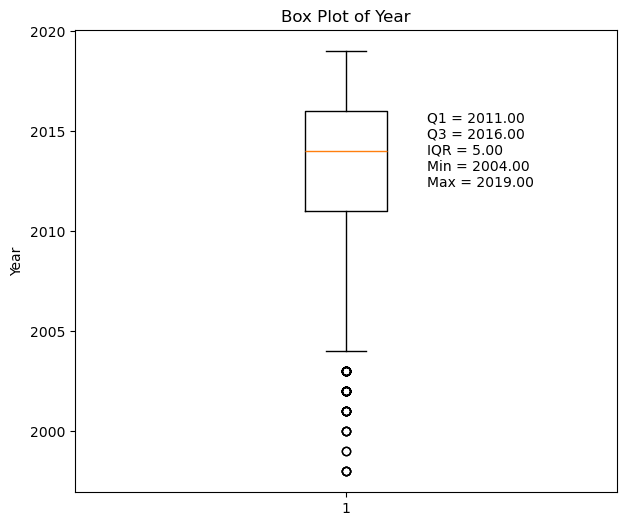

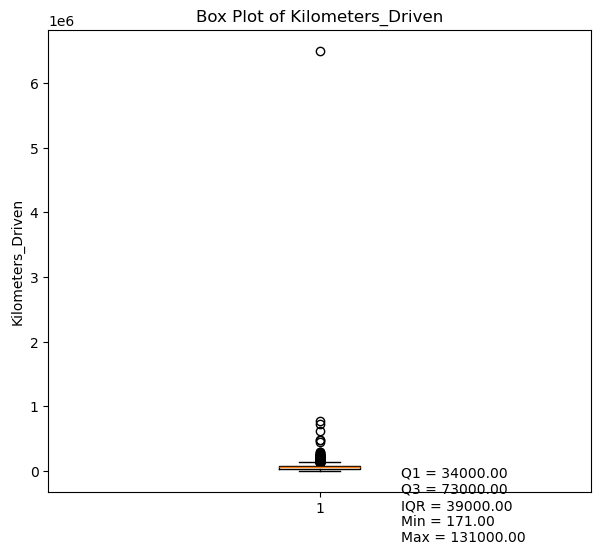

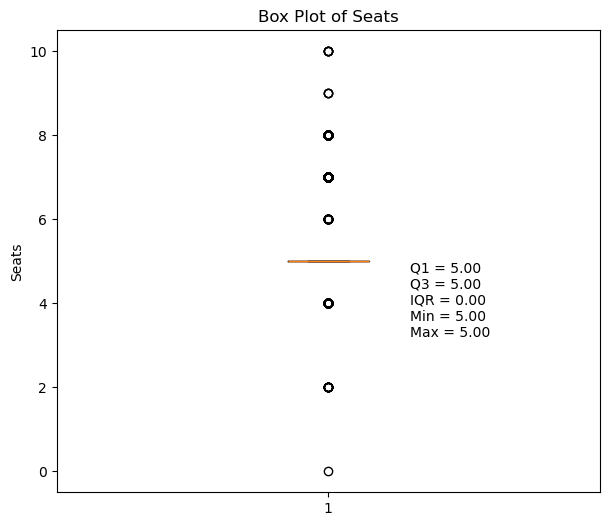

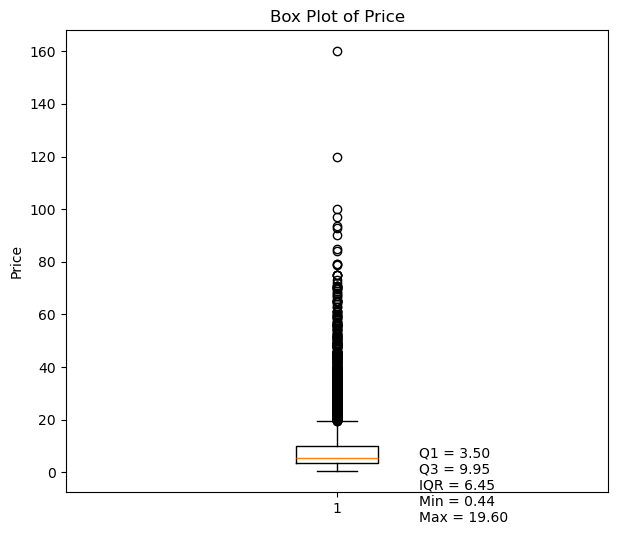

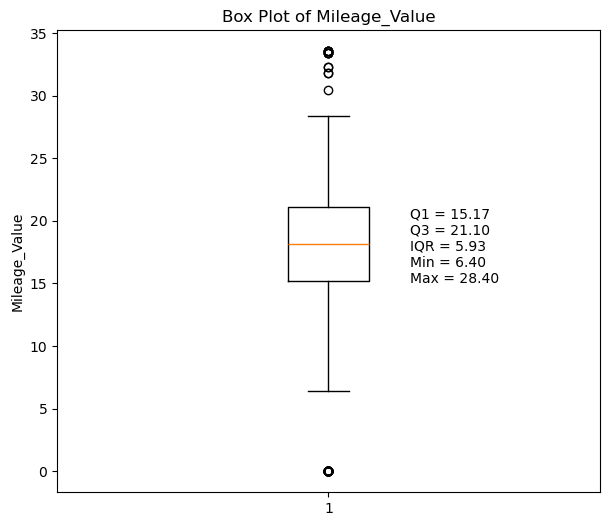

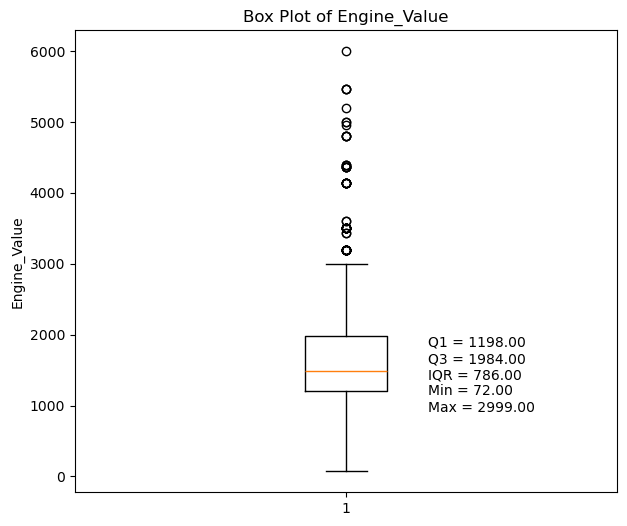

In [91]:
import matplotlib.pyplot as plt

for col in numeric_cols:
    data = df[col].dropna()

    # Calculate quartiles
    Q1 = data.quantile(0.25)
    Q3 = data.quantile(0.75)
    IQR = Q3 - Q1

    # Outlier boundaries
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    # Actual Min and Max values inside the whiskers
    min_value = data[data >= lower_bound].min()
    max_value = data[data <= upper_bound].max()

    # Draw Box Plot
    plt.figure(figsize=(7, 6))
    plt.boxplot(data)

    plt.title(f"Box Plot of {col}")
    plt.ylabel(col)

    # Show information on the plot
    info = (
        f"Q1 = {Q1:.2f}\n"
        f"Q3 = {Q3:.2f}\n"
        f"IQR = {IQR:.2f}\n"
        f"Min = {min_value:.2f}\n"
        f"Max = {max_value:.2f}"
    )

    plt.text(
        1.15,
        Q3,
        info,
        fontsize=10,
        verticalalignment="top"
    )

    plt.show()



In [88]:
numeric_cols

Index(['Year', 'Kilometers_Driven', 'Seats', 'Price', 'Mileage_Value',
       'Engine_Value'],
      dtype='object')

In [89]:
df_copy["Year"].value_counts()

Year
2014    795
2015    741
2016    740
2013    648
2017    586
2012    572
2011    461
2010    338
2018    298
2009    196
2008    169
2007    123
2019    102
2006     75
2005     55
2004     29
2003     15
2002     14
2001      7
2000      4
1998      4
1999      2
Name: count, dtype: int64

In [92]:
#drop car before 2004
df_copy = df_copy[df_copy["Year"] > 2004]

In [98]:
import matplotlib.pyplot as plt


def plot_boxplot_with_info(df_copy, col):

    data = df_copy[col].dropna()

    # Calculate quartiles
    Q1 = data.quantile(0.25)
    Q3 = data.quantile(0.75)
    IQR = Q3 - Q1

    # Outlier boundaries
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    # Actual Min and Max values inside the whiskers
    min_value = data[data >= lower_bound].min()
    max_value = data[data <= upper_bound].max()

    # Draw Box Plot
    plt.figure(figsize=(7, 6))
    plt.boxplot(data)

    plt.title(f"Box Plot of {col}")
    plt.ylabel(col)

    # Show information on the plot
    info = (
        f"Q1 = {Q1:.2f}\n"
        f"Q3 = {Q3:.2f}\n"
        f"IQR = {IQR:.2f}\n"
        f"Min = {min_value:.2f}\n"
        f"Max = {max_value:.2f}"
    )

    plt.text(
        1.15,
        Q3,
        info,
        fontsize=10,
        verticalalignment="top"
    )

    plt.show()



In [97]:
# order df_copy by Kilometers_Driven , and get top 10 rows with highest Kilometers_Driven
df_copy.sort_values("Kilometers_Driven", ascending=False).head(10)

,Name,Location,Year,Kilometers_Driven,Fuel_Type,Transmission,Owner_Type,Engine,Power,Seats,Price,Mileage_Value,Mileage_unit,Engine_Value
2328,BMW X5 xDrive 30d M Sport,Chennai,2017,6500000,Diesel,Automatic,First,2993 CC,258 bhp,5.0,65.00,15.97,kmpl,2993.0
340,Skoda Octavia Ambition Plus 2.0 TDI AT,Kolkata,2013,775000,Diesel,Automatic,First,1968 CC,141 bhp,5.0,7.50,19.30,kmpl,1968.0
1860,Volkswagen Vento Diesel Highline,Chennai,2013,720000,Diesel,Manual,First,1598 CC,103.6 bhp,5.0,5.90,20.54,kmpl,1598.0
358,Hyundai i10 Magna 1.2,Chennai,2009,620000,Petrol,Manual,First,1197 CC,78.9 bhp,5.0,2.70,20.36,kmpl,1197.0
3092,Honda City i VTEC SV,Kolkata,2015,480000,Petrol,Manual,First,1497 CC,117.3 bhp,5.0,5.00,17.40,kmpl,1497.0
2823,Volkswagen Jetta 2013-2015 2.0L TDI Highline AT,Chennai,2015,480000,Diesel,Automatic,First,1968 CC,138.03 bhp,5.0,13.00,16.96,kmpl,1968.0
4491,Hyundai i20 Magna Optional 1.2,Bangalore,2013,445000,Petrol,Manual,First,1197 CC,82.9 bhp,5.0,4.45,18.50,kmpl,1197.0
3649,Tata Indigo LS,Jaipur,2008,300000,Diesel,Manual,First,1405 CC,70 bhp,5.0,1.00,17.00,kmpl,1405.0
1528,Toyota Innova 2.5 G (Diesel) 8 Seater BS IV,Hyderabad,2005,299322,Diesel,Manual,First,2494 CC,102 bhp,8.0,4.00,12.80,kmpl,2494.0
1975,Skoda Superb 1.8 TSI MT,Pune,2012,282000,Petrol,Manual,First,1798 CC,160 bhp,5.0,3.30,13.14,kmpl,1798.0


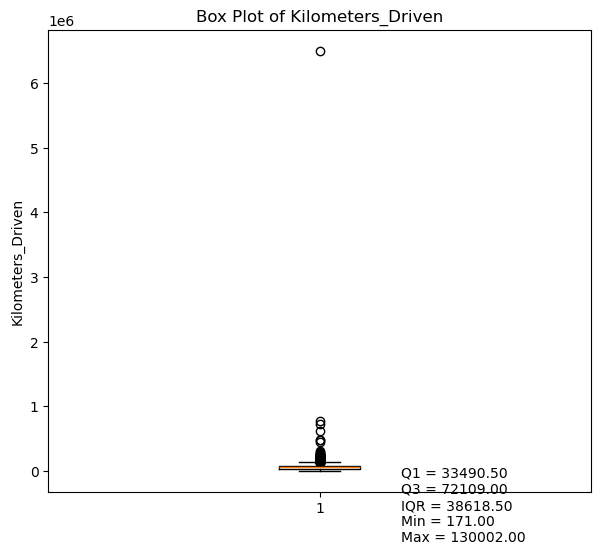

In [99]:
plot_boxplot_with_info(df_copy, "Kilometers_Driven")

In [100]:
# drop row with Kilometers_Driven = 6500000
df_copy = df_copy[df_copy["Kilometers_Driven"] != 6500000]

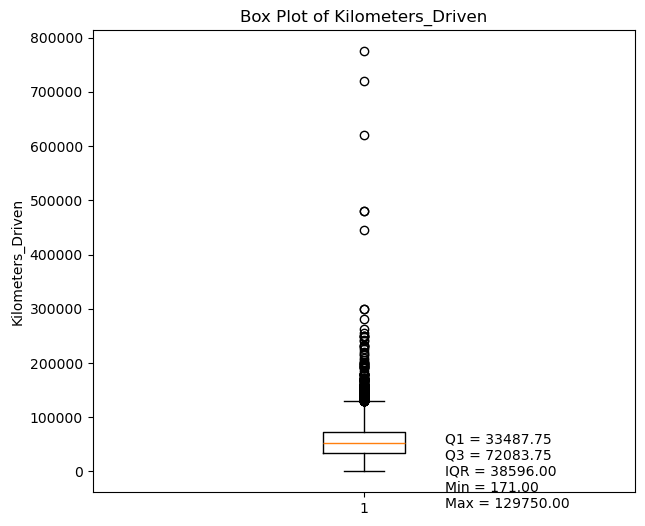

In [101]:
plot_boxplot_with_info(df_copy, "Kilometers_Driven")

In [102]:
df_copy["Kilometers_Driven"].describe()

count      5898.000000
mean      57093.062055
std       37585.885897
min         171.000000
25%       33487.750000
50%       52465.500000
75%       72083.750000
max      775000.000000
Name: Kilometers_Driven, dtype: float64

In [107]:
df_copy[df_copy["Kilometers_Driven"] >= 210000].info()

<class 'pandas.core.frame.DataFrame'>
Index: 26 entries, 29 to 5834
Data columns (total 14 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Name               26 non-null     object 
 1   Location           26 non-null     object 
 2   Year               26 non-null     int64  
 3   Kilometers_Driven  26 non-null     int64  
 4   Fuel_Type          26 non-null     object 
 5   Transmission       26 non-null     object 
 6   Owner_Type         26 non-null     object 
 7   Engine             26 non-null     object 
 8   Power              26 non-null     object 
 9   Seats              26 non-null     float64
 10  Price              26 non-null     float64
 11  Mileage_Value      26 non-null     float64
 12  Mileage_unit       26 non-null     object 
 13  Engine_Value       26 non-null     float64
dtypes: float64(4), int64(2), object(8)
memory usage: 3.0+ KB


In [ ]:
df_copy[df_copy["Kilometers_Driven"] >= 210000]

,Name,Location,Year,Kilometers_Driven,Fuel_Type,Transmission,Owner_Type,Engine,Power,Seats,Price,Mileage_Value,Mileage_unit,Engine_Value,Brand
29,Toyota Innova 2.5 V Diesel 7-seater,Mumbai,2007,262000,Diesel,Manual,Fourth & Above,2494 CC,102 bhp,7.0,4.00,12.80,kmpl,2494.0,Toyota
77,Toyota Innova 2.0 G1,Chennai,2006,230000,Petrol,Manual,Third,1998 CC,132 bhp,8.0,4.50,12.40,kmpl,1998.0,Toyota
181,Ford Fiesta 1.4 TDCi EXI Limited Edition,Chennai,2006,216000,Diesel,Manual,Second,1399 CC,68 bhp,5.0,1.45,17.80,kmpl,1399.0,Ford
340,Skoda Octavia Ambition Plus 2.0 TDI AT,Kolkata,2013,775000,Diesel,Automatic,First,1968 CC,141 bhp,5.0,7.50,19.30,kmpl,1968.0,Skoda
358,Hyundai i10 Magna 1.2,Chennai,2009,620000,Petrol,Manual,First,1197 CC,78.9 bhp,5.0,2.70,20.36,kmpl,1197.0,Hyundai
838,Mahindra Xylo H4,Chennai,2016,215000,Diesel,Manual,First,2179 CC,118.3 bhp,7.0,7.50,14.02,kmpl,2179.0,Mahindra
1068,Toyota Etios Liva GD,Pune,2012,225000,Diesel,Manual,Second,1364 CC,null bhp,5.0,2.60,23.59,kmpl,1364.0,Toyota
1101,Toyota Innova 2.5 V Diesel 7-seater,Chennai,2011,248000,Diesel,Manual,Second,2494 CC,102 bhp,7.0,9.20,12.80,kmpl,2494.0,Toyota
1442,Honda City 1.5 S MT,Delhi,2009,231673,Petrol,Manual,First,1497 CC,118 bhp,5.0,2.60,17.00,kmpl,1497.0,Honda
1528,Toyota Innova 2.5 G (Diesel) 8 Seater BS IV,Hyderabad,2005,299322,Diesel,Manual,First,2494 CC,102 bhp,8.0,4.00,12.80,kmpl,2494.0,Toyota


In [110]:
df_copy["Brand"] = df_copy["Name"].str.split().str[0]